# Trabalho 3 - Mineração de dados
Este trabalho tem como objetivo  aplicar técnicas de aprendizado não supervisionado, especificamente clusterização, para investigar a existência de grupos de estudantes com padrões semelhantes de interação educacional.

O dataset escolhido foi: 
- xAPI-Edu-Data

### Quais perfis de engajamento podem ser identificados entre estudantes a partir de suas interações educacionais, e como esses perfis se relacionam com o desempenho acadêmico?


In [212]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler

caminho = Path("datas/xAPI-Edu-Data.csv")

df_original = pd.read_csv(caminho, encoding='utf-8')

df_original.info()

display(df_original.head(10))

<class 'pandas.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   gender                    480 non-null    str  
 1   NationalITy               480 non-null    str  
 2   PlaceofBirth              480 non-null    str  
 3   StageID                   480 non-null    str  
 4   GradeID                   480 non-null    str  
 5   SectionID                 480 non-null    str  
 6   Topic                     480 non-null    str  
 7   Semester                  480 non-null    str  
 8   Relation                  480 non-null    str  
 9   raisedhands               480 non-null    int64
 10  VisITedResources          480 non-null    int64
 11  AnnouncementsView         480 non-null    int64
 12  Discussion                480 non-null    int64
 13  ParentAnsweringSurvey     480 non-null    str  
 14  ParentschoolSatisfaction  480 non-null    str  
 15  

,gender,NationalITy,PlaceofBirth,StageID,GradeID,SectionID,Topic,Semester,Relation,raisedhands,VisITedResources,AnnouncementsView,Discussion,ParentAnsweringSurvey,ParentschoolSatisfaction,StudentAbsenceDays,Class
0,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,15,16,2,20,Yes,Good,Under-7,M
1,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,20,20,3,25,Yes,Good,Under-7,M
2,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,10,7,0,30,No,Bad,Above-7,L
3,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,30,25,5,35,No,Bad,Above-7,L
4,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,40,50,12,50,No,Bad,Above-7,M
5,F,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,42,30,13,70,Yes,Bad,Above-7,M
6,M,KW,KuwaIT,MiddleSchool,G-07,A,Math,F,Father,35,12,0,17,No,Bad,Above-7,L
7,M,KW,KuwaIT,MiddleSchool,G-07,A,Math,F,Father,50,10,15,22,Yes,Good,Under-7,M
8,F,KW,KuwaIT,MiddleSchool,G-07,A,Math,F,Father,12,21,16,50,Yes,Good,Under-7,M
9,F,KW,KuwaIT,MiddleSchool,G-07,B,IT,F,Father,70,80,25,70,Yes,Good,Under-7,M


### Qualidade dos dados

##### Valores ausentes

In [213]:
df_original.isna().sum()

gender                      0
NationalITy                 0
PlaceofBirth                0
StageID                     0
GradeID                     0
SectionID                   0
Topic                       0
Semester                    0
Relation                    0
raisedhands                 0
VisITedResources            0
AnnouncementsView           0
Discussion                  0
ParentAnsweringSurvey       0
ParentschoolSatisfaction    0
StudentAbsenceDays          0
Class                       0
dtype: int64

#### Registros duplicados

In [214]:
df_original.duplicated().sum()

np.int64(2)

#### Conclusões

Não foram encontrados valores ausentes, o que facilita o pré-processamento e evita a necessidade de preencher informações faltantes. Foram encontrados apenas dois registros com informações completamente repetidas, mas como não existe um identificador único para cada estudante, não é possível afirmar que se trata de um erro. 

### Análise preliminar

Foram analisadas quatro variáveis: raisedhands, VisITedResources, AnnouncementsView e Discussion

In [215]:
variaveis = [
    "raisedhands",
    "VisITedResources",
    "AnnouncementsView",
    "Discussion"
]

df_original[variaveis].describe().round(2)


,raisedhands,VisITedResources,AnnouncementsView,Discussion
count,480.00,480.00,480.00,480.00
mean,46.78,54.80,37.92,43.28
std,30.78,33.08,26.61,27.64
min,0.00,0.00,0.00,1.00
25%,15.75,20.00,14.00,20.00
50%,50.00,65.00,33.00,39.00
75%,75.00,84.00,58.00,70.00
max,100.00,99.00,98.00,99.00


Ao analisar as variáveis comportamentais, percebemos que o acesso aos recursos educacionais apresenta a maior média (54,80), enquanto a visualização de avisos possui a menor (37,92).

Também é possível observar uma variação considerável no comportamento dos estudantes, principalmente no acesso aos recursos, que apresenta o maior desvio padrão (33,08). Isso indica que existem diferenças importantes na quantidade de interações registradas.

Outro ponto interessante é que a mediana de acesso aos recursos (65) é maior que a média (54,80), sugerindo a presença de estudantes com poucos acessos que acabam reduzindo a média geral.

Essas diferenças tornam interessante investigar se existem grupos de estudantes com padrões semelhantes de interação.

Class
M    211
H    142
L    127
Name: count, dtype: int64


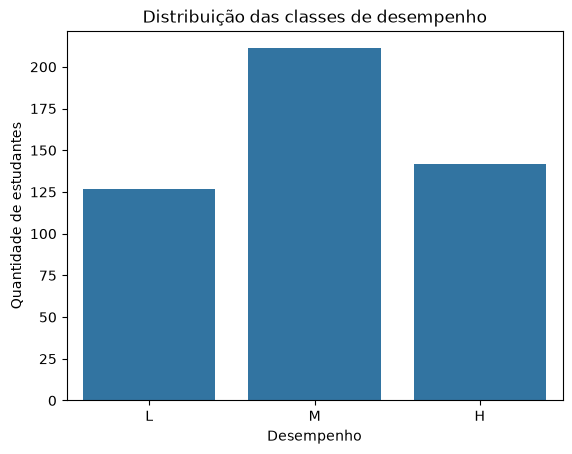

In [216]:

print(df_original["Class"].value_counts())

sns.countplot(
    data=df_original,
    x="Class",
    order=["L", "M", "H"]
)

plt.title("Distribuição das classes de desempenho")
plt.xlabel("Desempenho")
plt.ylabel("Quantidade de estudantes")
plt.show()

Em relação ao desempenho acadêmico, a maior parte dos estudantes está classificada no nível médio (44%), seguida dos níveis alto (29,6%) e baixo (26,5%).

Apesar da predominância do desempenho médio, as três categorias possuem uma quantidade significativa de estudantes. Isso será interessante nas próximas etapas, quando poderemos investigar se determinados padrões de interação estão associados a diferentes níveis de desempenho.

A variável de desempenho não será utilizada para formar os clusters, apenas para ajudar na interpretação dos grupos encontrados.

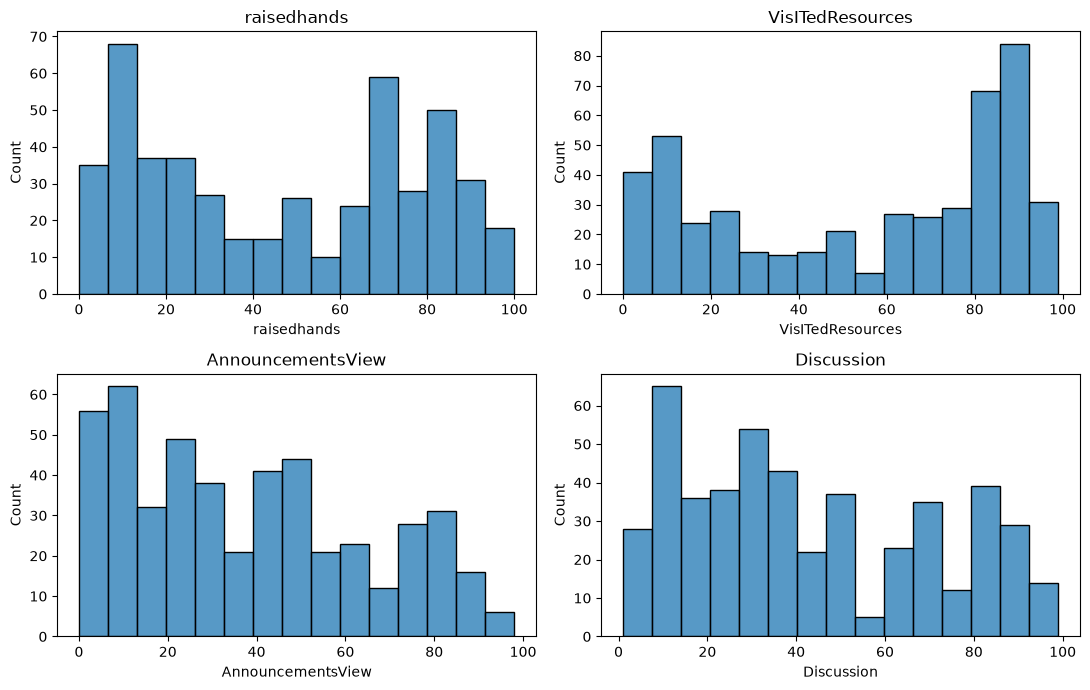

In [217]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

for ax, coluna in zip(axes.flat, variaveis):
    sns.histplot(
        df_original[coluna],
        bins=15,
        ax=ax
    )
    ax.set_title(coluna)

plt.tight_layout()
plt.show()

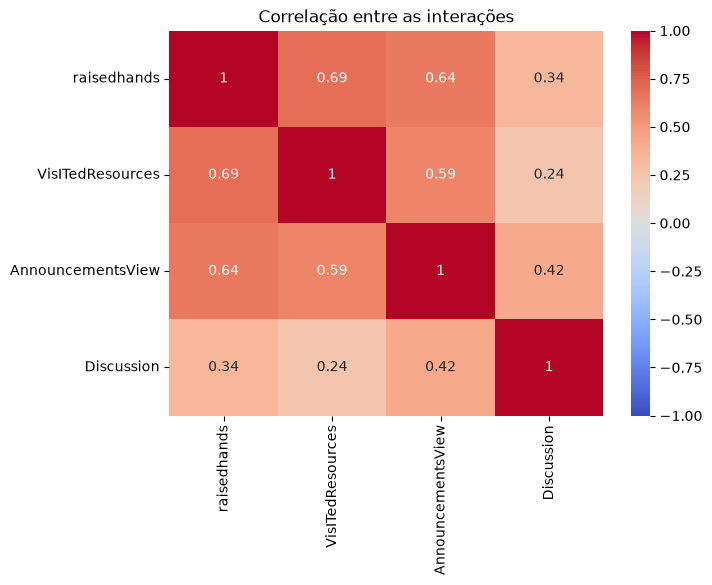

In [218]:
correlacoes = df_original[variaveis].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlacoes,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Correlação entre as interações")
plt.show()

Nos histogramas, percebemos que os estudantes apresentam diferentes níveis de interação. Em algumas variáveis, como participação em aula e acesso aos recursos educacionais, existem concentrações tanto em valores baixos quanto em valores altos.

A matriz de correlação também revelou algumas relações relevantes. A participação em aula e o acesso aos recursos apresentaram uma correlação positiva de 0,69, o que indica que estudantes que participam mais das aulas também tendem a acessar mais materiais.

Porém, a correlação entre o acesso aos recursos e a participação em discussões foi de apenas 0,24. Isso indica que acessar muitos materiais não significa necessariamente participar mais das discussões.

Essas diferenças reforçam a possibilidade de existirem diferentes padrões de engajamento entre os estudantes.

### Tratamento dos dados

Para preparar os dados, foram selecionadas quatro variáveis relacionadas ao comportamento dos estudantes: participação em aula, acesso aos recursos, visualização de avisos e participação em discussões.

A variável de desempenho acadêmico foi mantida fora dessa etapa, pois será utilizada posteriormente apenas para interpretar os resultados.

Também foi aplicada a padronização das características, para que diferenças de escala e dispersão não influenciem excessivamente os cálculos de distância. Os registros originais foram preservados, permitindo comparar os dados antes e depois da transformação.

(480, 4)


,raisedhands,VisITedResources,AnnouncementsView,Discussion
0,15,16,2,20
1,20,20,3,25
2,10,7,0,30
3,30,25,5,35
4,40,50,12,50


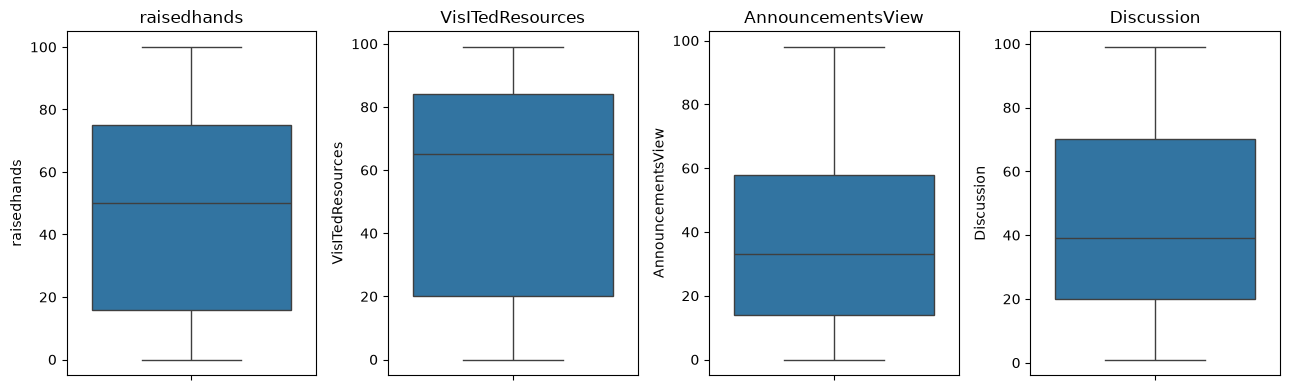

In [219]:
X = df_original[variaveis].copy()

print(X.shape)
display(X.head())

fig, axes = plt.subplots(1, 4, figsize=(13, 4))

for ax, coluna in zip(axes, variaveis):
    sns.boxplot(y=X[coluna], ax=ax)
    ax.set_title(coluna)

plt.tight_layout()
plt.show()

A análise dos boxplots permite identificar possíveis valores extremos nas interações dos estudantes. Entretanto, valores muito altos ou baixos não representam necessariamente erros, pois alguns alunos podem realmente participar mais ou menos das atividades.

Como não foram identificadas evidências suficientes de que esses valores sejam incorretos, optamos por manter os registros, preservando as diferenças de comportamento entre os estudantes.

In [220]:
scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=variaveis,
    index=X.index
)

display(X_scaled.describe().round(2))


,raisedhands,VisITedResources,AnnouncementsView,Discussion
count,480.00,480.00,480.00,480.00
mean,0.00,0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00
min,-1.52,-1.66,-1.43,-1.53
25%,-1.01,-1.05,-0.90,-0.84
50%,0.10,0.31,-0.19,-0.16
75%,0.92,0.88,0.76,0.97
max,1.73,1.34,2.26,2.02


In [221]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"],
    index=X.index
)

print(
    "Variância explicada:",
    pca.explained_variance_ratio_
)

print(
    "Variância acumulada:",
    pca.explained_variance_ratio_.sum()
)

Variância explicada: [0.62714744 0.20387185]
Variância acumulada: 0.8310192894132183


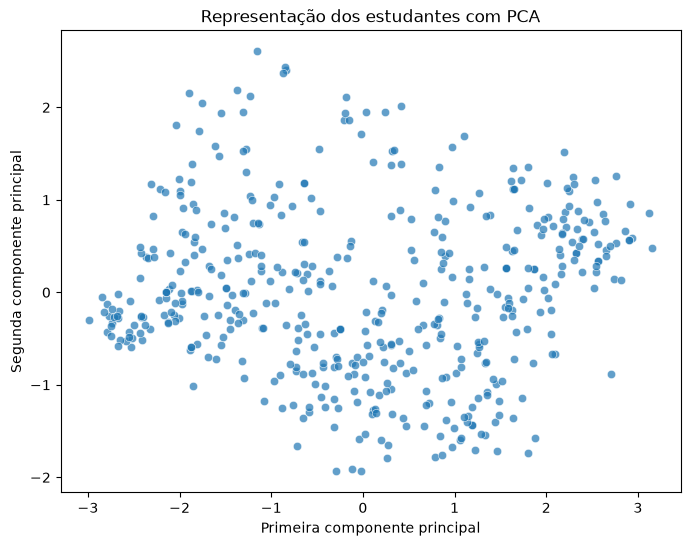

In [222]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    alpha=0.7
)

plt.title("Representação dos estudantes com PCA")
plt.xlabel("Primeira componente principal")
plt.ylabel("Segunda componente principal")
plt.show()

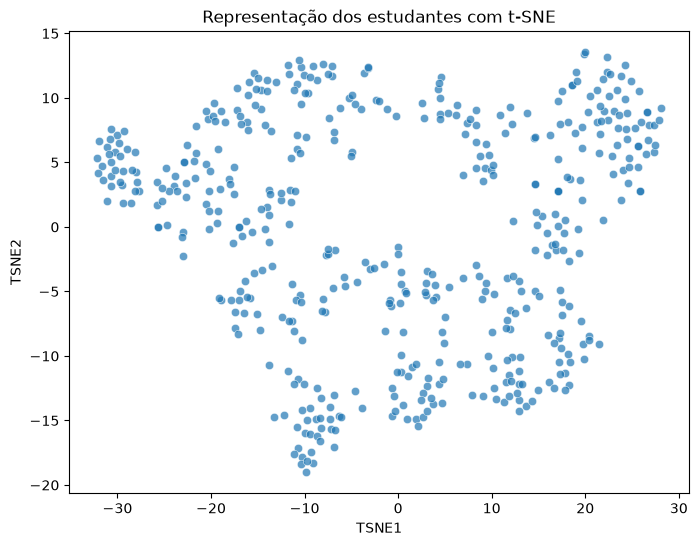

In [223]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_scaled)

df_tsne = pd.DataFrame(
    X_tsne,
    columns=["TSNE1", "TSNE2"],
    index=X.index
)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_tsne,
    x="TSNE1",
    y="TSNE2",
    alpha=0.7
)

plt.title("Representação dos estudantes com t-SNE")
plt.show()

### Representação dos dados

Para facilitar a visualização dos padrões de comportamento dos estudantes, foram utilizadas duas técnicas de redução de dimensionalidade: PCA e t-SNE.

O PCA foi aplicado para representar as quatro variáveis comportamentais em duas componentes principais. A primeira componente explicou aproximadamente 62,71% da variância dos dados e a segunda, 20,39%. Juntas, conseguiram preservar cerca de **83,10% da variância total**, o que indica que a representação em duas dimensões manteve boa parte das informações.

No gráfico do PCA, percebemos que os estudantes estão distribuídos de maneira relativamente contínua, embora existam algumas regiões com maior concentração de pontos. Não aparecem separações completamente definidas entre os possíveis grupos.

Já o t-SNE apresentou uma distribuição visual diferente, destacando algumas regiões de maior concentração e proximidade entre os estudantes.

Essas representações ajudam a compreender melhor a estrutura dos dados e mostram que existem diferenças nos padrões de interação. Entretanto, ainda não podemos afirmar quantos grupos existem ou se eles são bem definidos, pois isso dependerá das próximas etapas da análise.